# Combine EDA

I analyzed combine coverage, player matching, and size/speed profiles for the 2010–2022 draft classes. Surplus correlations use 2010–2018. I kept every draft pick in the bridge and excluded specialists from the position analysis.

Data: [nflverse](https://nflreadpy.nflverse.com/api/load_functions/), downloaded November 8, 2026. [Measurement units](https://nflreadr.nflverse.com/articles/dictionary_combine.html). Run `python -m src.data.pull_nfl` if the raw cache is missing.

This run uses Vincent’s [outcome definition (PR #1)](https://github.com/abhik026/bruin-draft-analytics/pull/1), Justin’s [baseline (PR #2)](https://github.com/abhik026/bruin-draft-analytics/pull/2), and Gonzalo’s [position overrides (PR #3)](https://github.com/abhik026/bruin-draft-analytics/pull/3). Those versions must be present to rerun it; all three PRs were open on November 15, 2026.

In [1]:
from pathlib import Path
import sys

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/utils.py').exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, Markdown, display

from src.utils import RAW_NFL, INTERIM, CLASS_MIN, CLASS_MAX, POSITION_GROUPS, pick_tier, to_pos_group
from src.features.combine import (COMBINE_COLS, build_id_bridge, combine_coverage,
                                  coverage_counts, size_speed_profiles, test_surplus_correlations)
from src.features.outcome import get_outcome, mature_classes, OUTCOME_METRIC, MATURE_CLASS_MAX
from src.features.baseline import fit_baseline, add_surplus

pd.set_option('display.max_rows', 25)
pd.set_option('display.max_columns', 14)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight'})
TEST_NAMES = {'height_in': 'Height (in)', 'weight': 'Weight (lb)', 'forty': '40 yd (s)',
              'vertical': 'Vertical (in)', 'broad_jump': 'Broad jump (in)',
              'bench': 'Bench (reps)', 'cone': '3-cone (s)', 'shuttle': 'Shuttle (s)'}

def full_table(table, caption, decimals=3):
    html = table.to_html(index=False, float_format=lambda x: f'{x:.{decimals}f}', na_rep='—')
    display(HTML(f'<details><summary>{caption} ({len(table):,} rows)</summary>{html}</details>'))

paths = {name: RAW_NFL / f'{name}.parquet' for name in ['draft_picks', 'combine', 'players']}
missing = [str(path) for path in paths.values() if not path.exists()]
assert not missing, f'Missing cached tables: {missing}. Run python -m src.data.pull_nfl.'
draft, combine, players = [pd.read_parquet(paths[name]) for name in paths]

overrides_path = root / 'src/data/position_overrides.csv'
assert overrides_path.exists(), 'This notebook requires the position overrides from PR #3.'
position_overrides = pd.read_csv(overrides_path)
bridge = build_id_bridge(draft, combine, players, position_overrides=position_overrides)
eligible_draft = draft[draft.season.between(CLASS_MIN, CLASS_MAX)].copy()
assert len(bridge) == len(eligible_draft)
assert not bridge.duplicated(['season', 'pick']).any()
assert set(map(tuple, bridge[['season', 'pick']].to_numpy())) == set(map(tuple, eligible_draft[['season', 'pick']].to_numpy()))
assert bridge.loc[bridge.has_combine, 'combine_row'].is_unique
assert bridge.loc[bridge.has_player_match, 'player_row'].is_unique
assert bridge.loc[bridge.has_combine, 'season'].eq(bridge.loc[bridge.has_combine, 'combine_season']).all()
assert bridge.loc[~bridge.has_combine, COMBINE_COLS].isna().all().all()

INTERIM.mkdir(parents=True, exist_ok=True)
bridge.to_parquet(INTERIM / 'nfl_id_bridge.parquet', index=False)

pd.testing.assert_frame_equal(bridge, pd.read_parquet(INTERIM / 'nfl_id_bridge.parquet'))
analysis = bridge[~bridge.excluded_position].copy()
analysis['position_label'] = analysis.pos_group.fillna('Unresolved')
analysis['pick_tier'] = pick_tier(analysis.pick)
position_order = POSITION_GROUPS + ['Unresolved']
coverage_position = combine_coverage(analysis, by='position_label').reindex(position_order)
coverage_year = combine_coverage(analysis, by='season')
counts_position = analysis.groupby('position_label').size().reindex(position_order)
counts_year = analysis.groupby('season').size()

## 1. Test coverage by position and year

I calculated coverage as measured players divided by **all drafted players in that group**, including those without combine records.

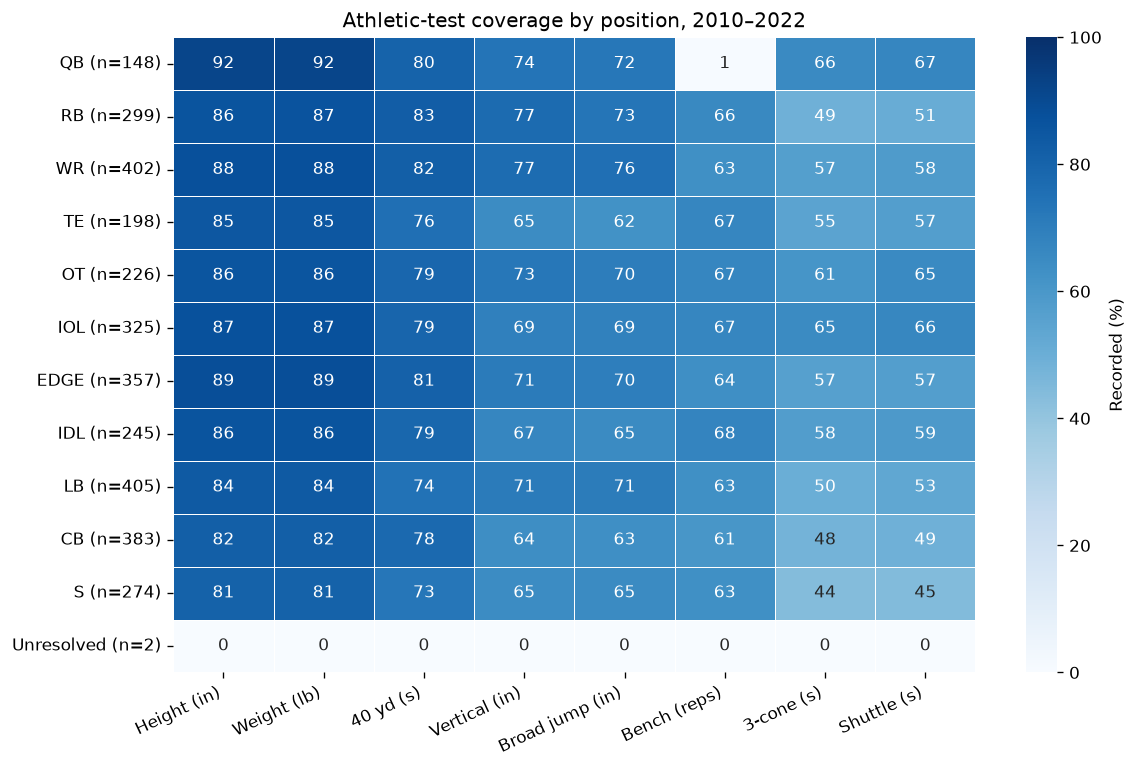

In [2]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.heatmap(coverage_position.astype(float) * 100, annot=True, fmt='.0f', cmap='Blues',
            vmin=0, vmax=100, linewidths=.5, cbar_kws={'label': 'Recorded (%)'}, ax=ax,
            xticklabels=[TEST_NAMES[x] for x in COMBINE_COLS],
            yticklabels=[f'{p} (n={counts_position[p]})' for p in position_order])
ax.set(title=f'Athletic-test coverage by position, {CLASS_MIN}–{CLASS_MAX}', xlabel='', ylabel='')
ax.tick_params(axis='x', labelrotation=25)
plt.setp(ax.get_xticklabels(), ha='right')
fig.tight_layout(); plt.show()

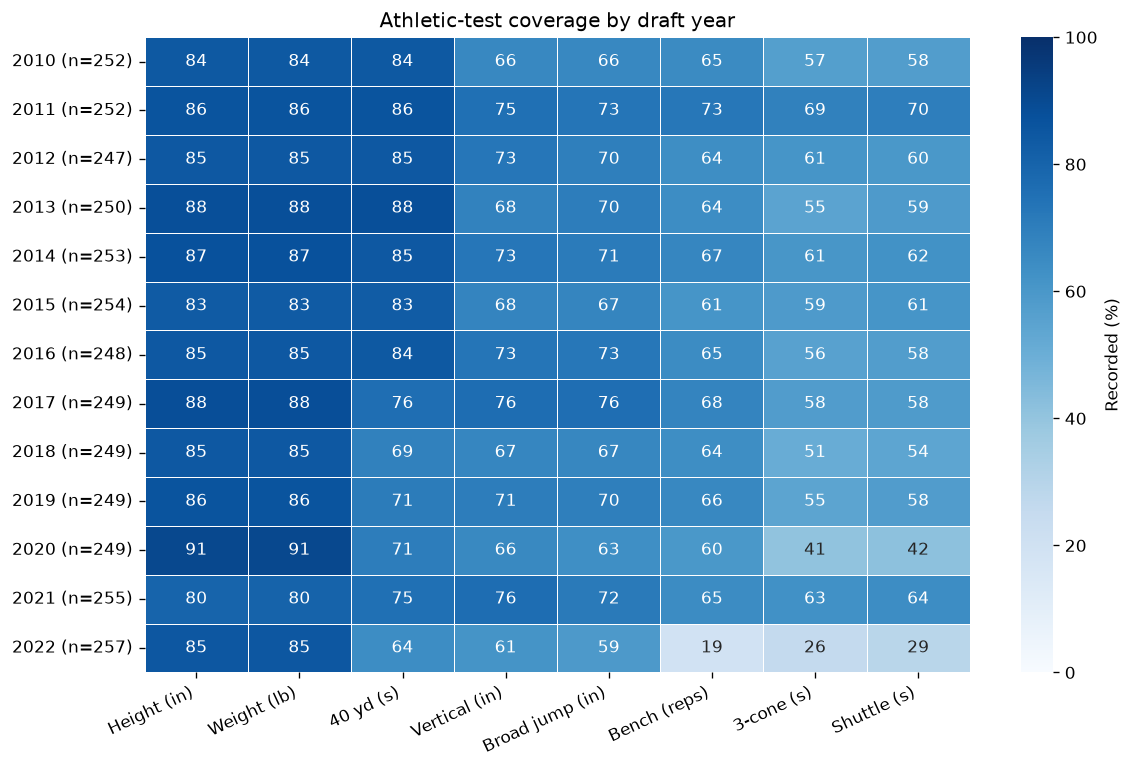

position_label,season,test,n_measured,n_drafted,coverage
CB,2010,height_in,17,24,0.708
CB,2011,height_in,26,33,0.788
CB,2012,height_in,23,30,0.767
CB,2013,height_in,22,24,0.917
CB,2014,height_in,26,28,0.929
CB,2015,height_in,22,29,0.759
CB,2016,height_in,27,31,0.871
CB,2017,height_in,26,28,0.929
CB,2018,height_in,19,25,0.760
CB,2019,height_in,24,31,0.774


In [3]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.heatmap(coverage_year.astype(float) * 100, annot=True, fmt='.0f', cmap='Blues',
            vmin=0, vmax=100, linewidths=.5, cbar_kws={'label': 'Recorded (%)'}, ax=ax,
            xticklabels=[TEST_NAMES[x] for x in COMBINE_COLS],
            yticklabels=[f'{year} (n={counts_year[year]})' for year in coverage_year.index])
ax.set(title='Athletic-test coverage by draft year', xlabel='', ylabel='')
ax.tick_params(axis='x', labelrotation=25)
plt.setp(ax.get_xticklabels(), ha='right')
fig.tight_layout(); plt.show()

coverage_detail = coverage_counts(analysis, by=['position_label', 'season'])
full_table(coverage_detail, 'Coverage counts by position, year, and test')

QB bench data is almost absent. Coverage also drops for several tests in 2022. In 2021, workouts moved to college pro days, so testing conditions differ. [NFL announcement](https://www.nfl.com/news/nfl-memo-details-different-format-for-combine-individual-workouts-will-be-held-o).

## 2. Position-label consistency

I compared labels using our shared position mapping and used Gonzalo’s overrides to fill unresolved labels. Existing resolved labels stay unchanged. Weights help check the EDGE/LB boundary.

In [4]:
positions = analysis[analysis.has_combine].copy()
positions['draft_group'] = positions.pos_draft.map(to_pos_group)
positions['combine_group'] = positions.pos_combine.map(to_pos_group)
comparable = positions[positions.draft_group.notna() & positions.combine_group.notna()]
disagreements = comparable[comparable.draft_group.ne(comparable.combine_group)]
display(pd.DataFrame({'comparable records': [len(comparable)], 'group disagreements': [len(disagreements)],
                      'disagreement_pct': [100 * len(disagreements) / len(comparable)]}).round(1))
display(disagreements.groupby(['pos_draft', 'pos_combine']).agg(
    players=('pick', 'size'), mean_weight_lb=('weight', 'mean')).sort_values('players', ascending=False).round(1))
full_table(disagreements[['season', 'pick', 'player_name', 'pos_draft', 'pos_combine', 'pos_players',
                          'pos_group', 'weight']], 'All comparable position disagreements')
full_table(analysis[analysis.position_unresolved][['season', 'pick', 'player_name', 'pos_draft', 'pos_players',
                                                 'pos_combine']], 'All unresolved positions')

,comparable records,group disagreements,disagreement_pct
0,2401,228,9.5


players  mean_weight_lb
pos_draft pos_combine                         
LB        OLB               91           241.4
DE        DL                25           269.1
          DT                19           300.6
G         OT                18           313.8
DT        DE                16           283.0
T         OG                10           320.5
LB        DE                 9           258.9
          EDGE               8           252.2
DL        DE                 5           266.2
DE        LB                 4           259.0
TE        FB                 4           244.2
LB        DL                 3           258.7
CB        S                  3           198.7
ILB       OLB                2           234.5
RB        WR                 2           207.0
OLB       ILB                2           246.0
S         CB                 1           206.0
C         OT                 1           309.0
RB        TE                 1           251.0
FB        TE                 1           246.0
DL        OLB                1           248.0
DE        TE                 1           252.0
WR        TE                 1           226.0

season,pick,player_name,pos_draft,pos_combine,pos_players,pos_group,weight
2010,10,Tyson Alualu,DT,DE,DE,EDGE,295.000
2010,19,Sean Weatherspoon,LB,OLB,LB,LB,239.000
2010,28,Jared Odrick,DE,DT,DE,EDGE,304.000
2010,40,Koa Misi,LB,OLB,OLB,EDGE,251.000
2010,43,Sergio Kindle,LB,OLB,LB,LB,250.000
2010,44,Lamarr Houston,DE,DT,LB,LB,305.000
2010,47,Daryl Washington,LB,OLB,ILB,LB,230.000
2010,53,Jermaine Cunningham,LB,DE,LB,LB,266.000
2010,56,Mike Neal,DE,DT,OLB,EDGE,294.000
2010,91,NaVorro Bowman,LB,OLB,MLB,LB,242.000


season,pick,player_name,pos_draft,pos_players,pos_combine
2010,203,Scotty McGee,DB,DB,—
2010,246,Ray Fisher,DB,—,—


I found 228 disagreements among 2,401 comparable records; LB versus OLB was the most common pair. I kept our OLB-to-EDGE rule. Gonzalo’s overrides resolve 36 previously unknown positions, leaving Scotty McGee and Ray Fisher unresolved.

## 3. ID bridge

I matched combine records by PFR ID and year, then draft pick/name or name/year/school. For the players table, I used PFR/GSIS IDs with the same fallback checks. I rejected conflicting IDs and ambiguous matches.

I saved the bridge as `data/interim/nfl_id_bridge.parquet`. Gonzalo can join it on **`(season, pick)`**. Every drafted player has a row, with unmatched rows flagged. The data file stays out of Git.

In [5]:
match_summary = pd.DataFrame({
    'source': ['Combine', 'Players'],
    'matched': [bridge.has_combine.sum(), bridge.has_player_match.sum()],
    'drafted': len(bridge)
})
match_summary['match_pct'] = 100 * match_summary.matched / match_summary.drafted
display(match_summary.round(2))

unmatched = bridge[~bridge.has_combine | ~bridge.has_player_match]
full_table(unmatched[['season', 'pick', 'player_name', 'college', 'pfr_id', 'gsis_id',
                      'has_combine', 'has_player_match']], 'Unmatched draft picks')
fallback = bridge[bridge.has_combine & bridge.combine_match_method.ne('pfr_id_year')]
full_table(fallback[['season', 'pick', 'player_name', 'combine_name', 'college', 'combine_school',
                     'combine_match_method']], 'Fallback matches')

,source,matched,drafted,match_pct
0,Combine,2853,3320,85.93
1,Players,3303,3320,99.49


season,pick,player_name,college,pfr_id,gsis_id,has_combine,has_player_match
2010,129,Jacques McClendon,Tennessee,McClJa20,00-0027729,False,True
2010,138,Walter McFadden,Auburn,McFaWa99,00-0027738,False,True
2010,143,Larry Hart,Central Arkansas,HartLa99,00-0027742,False,True
2010,148,Robert Johnson,Utah,JohnRo99,00-0027747,False,True
2010,152,Otis Hudson,Eastern Illinois,HudsOt20,00-0027751,False,True
2010,153,Austen Lane,Murray St.,LaneAu99,00-0027752,False,True
2010,168,Jonathan Crompton,Tennessee,CromJo00,00-0027767,False,True
2010,170,Fendi Onobun,Houston,OnobFe00,00-0027769,False,True
2010,171,Shann Schillinger,Montana,SchiSh99,00-0027770,False,True
2010,174,Dennis Morris,Louisiana Tech,—,—,False,False


season,pick,player_name,combine_name,college,combine_school,combine_match_method
2010,76,Chad Jones,Chad Jones,LSU,LSU,draft_pick_name
2010,172,Brent Bowden,Brent Bowden,Virginia Tech,Virginia Tech,draft_pick_name
2010,200,Charles Scott,Charles Scott,LSU,LSU,draft_pick_name
2010,207,Myron Rolle,Myron Rolle,Florida St.,Florida State,draft_pick_name
2010,216,Kyle Calloway,Kyle Calloway,Iowa,Iowa,draft_pick_name
2011,205,Pep Levingston,Pep Levingston,LSU,LSU,name_year_school
2015,202,A.J. Derby,AJ Derby,Arkansas,Arkansas,name_year_school
2016,127,Deiondre' Hall,Deiondre Hall,Northern Iowa,Northern Iowa,name_year_school
2017,130,Julién Davenport,Julien Davenport,Bucknell,Bucknell,name_year_school
2017,203,De'Angelo Henderson,DeAngelo Henderson,Coastal Carolina,Coastal Carolina,name_year_school


The bridge keeps 3,320 picks, with 467 missing combine links and 17 missing player-table links. Year checks separate reused IDs belonging to different people. Blank IDs never match each other.

## 4. Size and speed profiles

I calculated mean height, weight, and 40 time by position, with a separate sample count for each measurement.

In [6]:
profiles = size_speed_profiles(analysis).reindex(POSITION_GROUPS)
display(profiles.loc[:, pd.IndexSlice[:, ['count', 'mean']]].round(2))

height_in        weight         forty      
              count   mean  count    mean count  mean
pos_group                                            
QB              136  75.07    136  223.54   119  4.81
RB              258  70.59    259  215.83   247  4.54
WR              353  72.54    353  201.62   329  4.47
TE              168  76.37    168  250.75   150   4.7
OT              194  77.65    194  314.63   179  5.19
IOL             284  76.11    284  312.48   258  5.22
EDGE            316  75.43    316  265.05   289  4.77
IDL             211  75.11    211  308.59   193  5.07
LB              339  73.98    339  243.02   301  4.68
CB              314  71.61    314  194.06   298  4.47
S               221  72.04    221  205.13   200  4.52

Offensive linemen are the heaviest groups and have the slowest average 40 times. These averages are consistent with the broad position categories; they do not resolve individual EDGE/LB classification disputes.

## 5. Tests versus surplus value

I used Vincent’s `get_outcome` and `mature_classes` for 2010–2018, with Justin’s shared LOWESS baseline (`frac=0.1`, no robust reweighting, picks above 253 pooled at 253). The baseline includes every draft pick in that window before filtering positions or measured tests. Missing AV is set to zero under Vincent’s assumption that those players never played. Career AV is not four-year AV; the cutoff reduces, but does not eliminate, career-length differences.

I calculated Spearman correlations, complete-pair counts, and 95% bootstrap intervals (1,000 resamples, seed 42), leaving estimates blank below n=20. Intervals hold the fitted baseline fixed and are not adjusted for multiple comparisons. For timed tests, negative means faster times accompany greater surplus.

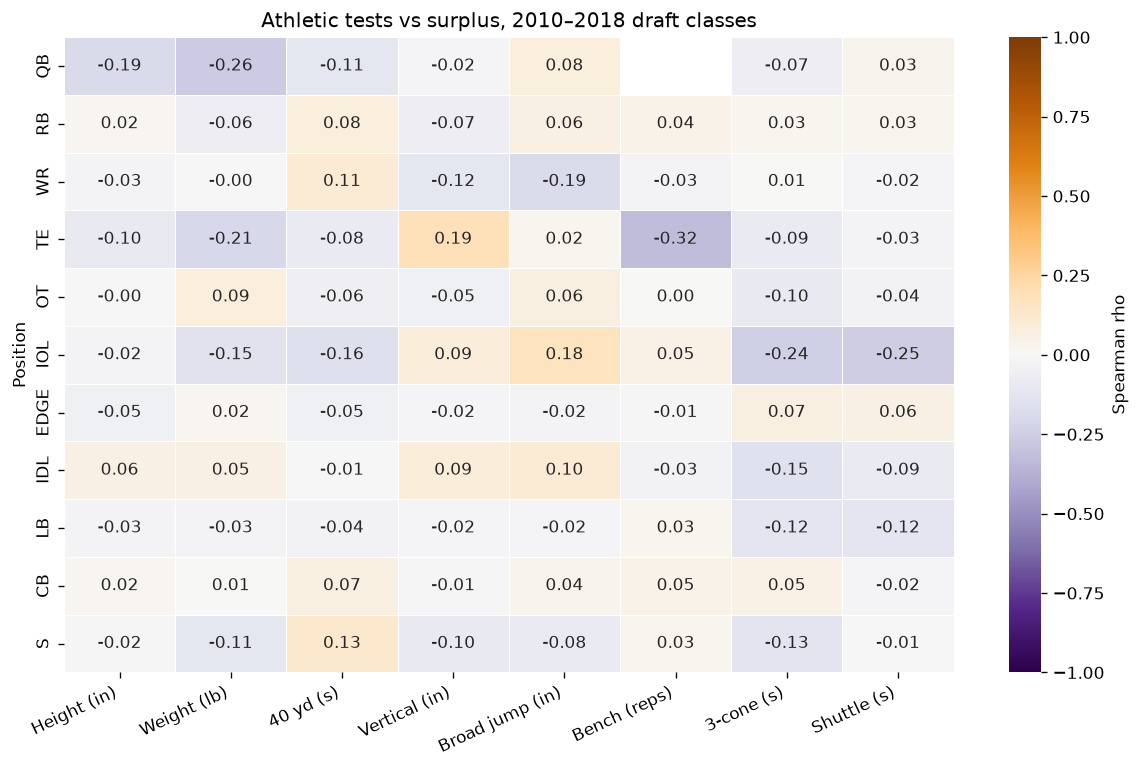

pos_group,test,n,rho,ci_low,ci_high
CB,height_in,208,0.017,-0.116,0.149
CB,weight,208,0.006,-0.141,0.141
CB,forty,206,0.067,-0.074,0.212
CB,vertical,171,-0.009,-0.163,0.148
CB,broad_jump,173,0.036,-0.111,0.192
CB,bench,166,0.045,-0.102,0.173
CB,cone,136,0.048,-0.116,0.213
CB,shuttle,141,-0.017,-0.177,0.160
EDGE,height_in,247,-0.053,-0.171,0.084
EDGE,weight,247,0.018,-0.108,0.151


In [7]:
baseline_data = mature_classes(eligible_draft).copy()
baseline_data['outcome'] = get_outcome(baseline_data)
baseline = fit_baseline(baseline_data)
assert baseline_data.outcome.notna().all()
assert baseline.index.max() == 253
surplus_data = add_surplus(baseline_data, baseline)
correlation_data = analysis[analysis.pos_group.notna()].merge(
    surplus_data[['season', 'pick', 'outcome', 'expected', 'surplus']],
    on=['season', 'pick'], how='inner', validate='one_to_one')
correlations = test_surplus_correlations(correlation_data, min_n=20, n_boot=1000, seed=42)
rho = correlations.pivot(index='pos_group', columns='test', values='rho').reindex(index=POSITION_GROUPS, columns=COMBINE_COLS)
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.heatmap(rho, annot=True, fmt='.2f', cmap='PuOr_r', center=0, vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={'label': 'Spearman rho'}, ax=ax,
            xticklabels=[TEST_NAMES[x] for x in COMBINE_COLS])
ax.set(title=f'Athletic tests vs surplus, {CLASS_MIN}–{MATURE_CLASS_MAX} draft classes', xlabel='', ylabel='Position')
ax.tick_params(axis='x', labelrotation=25)
plt.setp(ax.get_xticklabels(), ha='right')
fig.tight_layout(); plt.show()
full_table(correlations, 'All correlations, sample sizes, and 95% bootstrap intervals')

The strongest observed relationship is TE bench: rho −0.322, n=91, 95% interval [−0.488, −0.110]. More bench reps accompany lower surplus in this sample. QB bench has only one complete pair, so I do not estimate it. These are exploratory associations among measured players, not evidence of predictive accuracy.

## 6. Missingness patterns

I separated missing combine records from missing tests within matched records. The data does not identify why a player skipped a test.

In [8]:
missing_summary = pd.DataFrame({
    'no matched combine row': (~analysis.has_combine).sum(),
    'matched row, missing test': analysis.loc[analysis.has_combine, COMBINE_COLS].isna().sum(),
    'recorded test': analysis[COMBINE_COLS].notna().sum()
}).reindex(COMBINE_COLS)
assert missing_summary.sum(axis=1).eq(len(analysis)).all()
display(missing_summary.rename(index=TEST_NAMES))

matched_coverage = combine_coverage(analysis[analysis.has_combine], by='position_label').reindex(POSITION_GROUPS)
full_table((100 * matched_coverage).rename(columns=TEST_NAMES).round(1).reset_index(), 'Test coverage among matched players (%)', decimals=1)
by_tier = analysis.groupby('pick_tier', observed=True).agg(
    drafted=('pick', 'size'), matched=('has_combine', 'sum'))
by_tier['match_pct'] = 100 * by_tier.matched / by_tier.drafted
display(by_tier.round(1))

,no matched combine row,"matched row, missing test",recorded test
Height (in),455,15,2794
Weight (lb),455,14,2795
40 yd (s),455,246,2563
Vertical (in),455,514,2295
Broad jump (in),455,556,2253
Bench (reps),455,802,2007
3-cone (s),455,1028,1781
Shuttle (s),455,969,1840


position_label,Height (in),Weight (lb),40 yd (s),Vertical (in),Broad jump (in),Bench (reps),3-cone (s),Shuttle (s)
QB,100.0,100.0,87.5,80.2,78.7,0.7,71.3,72.8
RB,99.2,99.6,95.0,88.8,84.2,75.8,56.5,58.8
WR,99.4,99.4,92.7,87.0,85.6,71.6,64.2,66.2
TE,100.0,100.0,89.3,76.2,73.2,79.2,64.9,67.3
OT,99.5,99.5,91.8,84.1,81.5,77.4,70.8,75.9
IOL,100.0,100.0,90.8,79.2,78.9,76.8,74.6,76.1
EDGE,100.0,100.0,91.5,80.4,79.1,71.8,63.9,64.9
IDL,99.5,99.5,91.0,77.4,75.0,78.3,66.5,68.4
LB,99.1,99.1,88.0,84.5,83.9,74.6,59.6,63.2
CB,99.7,99.7,94.6,77.8,77.1,73.6,58.1,59.7


,drafted,matched,match_pct
pick_tier,,,
1-5,65,65,100.0
6-15,130,128,98.5
16-32,221,217,98.2
33-64,415,409,98.6
65-100,467,450,96.4
101+,1966,1540,78.3


Combine coverage falls to 78.3% for picks 101+, versus at least 96% in earlier tiers. Missing tests also differ by position; QB bench is the clearest example. Correlations therefore describe the measured subset and may be affected by who is missing.